2.13.0+cu130


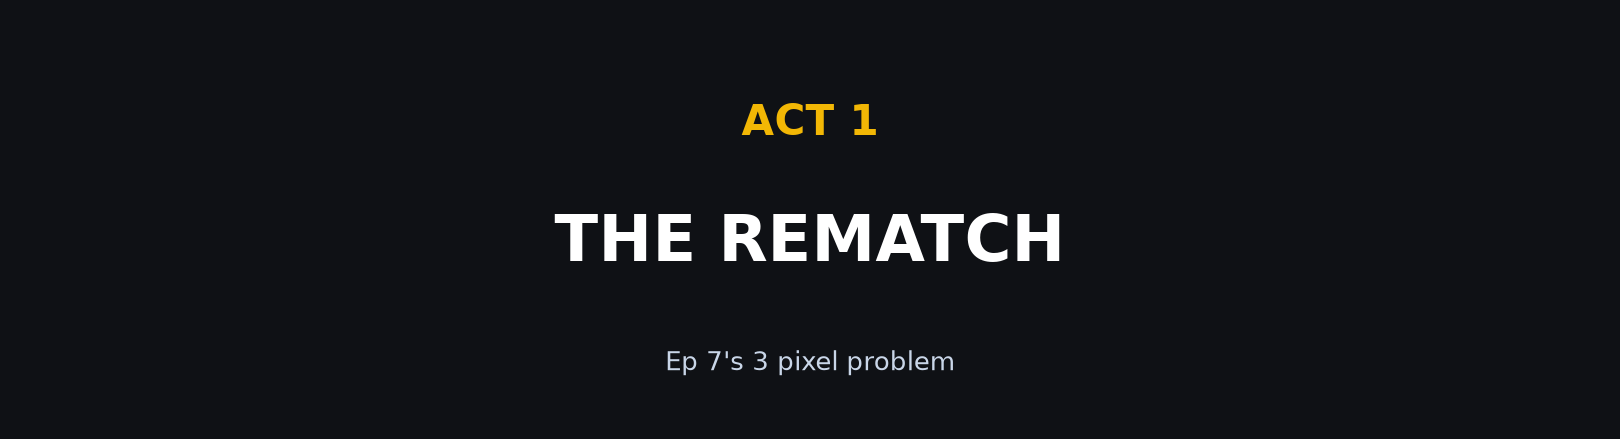

In [1]:
import copy
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets
import ep08_plots as viz

device = 'cuda' if torch.cuda.is_available() else "cpu"



torch.backends.cudnn.deterministic = True    # Same number for every run
torch.backends.cudnn.benchmark = False

print(torch.__version__)

viz.act(1, "The rematch", "Ep 7's 3 pixel problem")

In [2]:
train_set = datasets.FashionMNIST("data", train=True, download=True)
test_set = datasets.FashionMNIST("data", train=False, download = True)
classes = train_set.classes
X = train_set.data.float().unsqueeze(1) / 255
y = train_set.targets
X_train, y_train = X[:50000], y[:50000]
X_val, y_val = X[50000:], y[50000:]
X_test = test_set.data.float().unsqueeze(1) / 255
y_test = test_set.targets
print(X_train.shape, X_val.shape, X_test.shape)

100%|██████████| 26.4M/26.4M [02:28<00:00, 178kB/s]   
100%|██████████| 29.5k/29.5k [00:00<00:00, 195kB/s]
100%|██████████| 4.42M/4.42M [00:05<00:00, 833kB/s] 
100%|██████████| 5.15k/5.15k [00:00<00:00, 5.15MB/s]


torch.Size([50000, 1, 28, 28]) torch.Size([10000, 1, 28, 28]) torch.Size([10000, 1, 28, 28])


In [3]:
def picks(model, X):
    out = []
    with torch.no_grad():
        for i in range(0, len(X), 1000):     # 1000 photos at a time
            scores = model(X[i: i+1000].to(device))
            out.append(scores.argmax(dim = 1).cpu())
    return torch.cat(out)

def accuracy(model, X, y):
    return round((picks(model, X) == y).float().mean().item(), 3)

def sure(model, X, shelf):
    with torch.no_grad():
        chances = torch.softmax(model(X.to(device)), dim = 1)
    return chances[:, shelf].cpu()

def score(model, X, shelf):
    with torch.no_grad():
        return model(X.to(device))[:, shelf].cpu()

In [4]:
## Ep 7's assistant

def new_shop_model():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(784, 128), nn.ReLU(),
        nn.Linear(128, 64), nn.ReLU(),
        nn.Linear(64, 10),
    )

shop = new_shop_model().to(device)
shop.load_state_dict(torch.load("shop_model.pt"))  ## Loading the brain of the model
print("Board exam: ", accuracy(shop, X_test, y_test))

Board exam:  0.881


## The three pixel problem

In [7]:
def shift(X, k):
    moved = torch.roll(X, shifts = k, dims = 3)
    moved[:, :, :, :k] = 0  # Blank columns generated to be white
    return moved

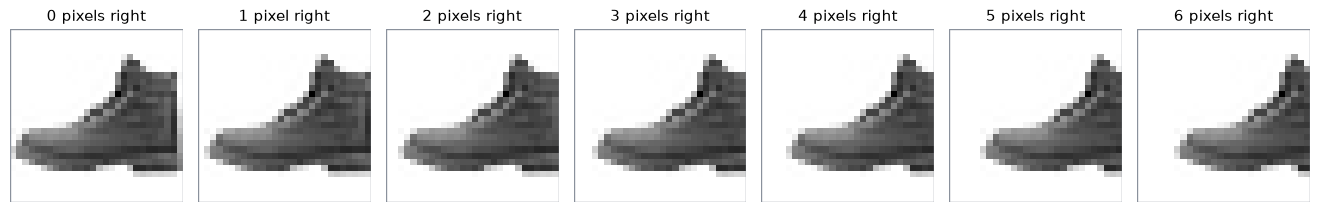

[0.89, 0.83, 0.573, 0.299, 0.235, 0.249, 0.207]


In [8]:
viz.show_slides(X_val[0], shift)
shop_slid = [accuracy(shop, shift(X_val, k), y_val) for k in range(7)]
print(shop_slid)

## A window of 9 numbers

torch.Size([1, 1, 28, 28]) -> torch.Size([1, 1, 28, 28])


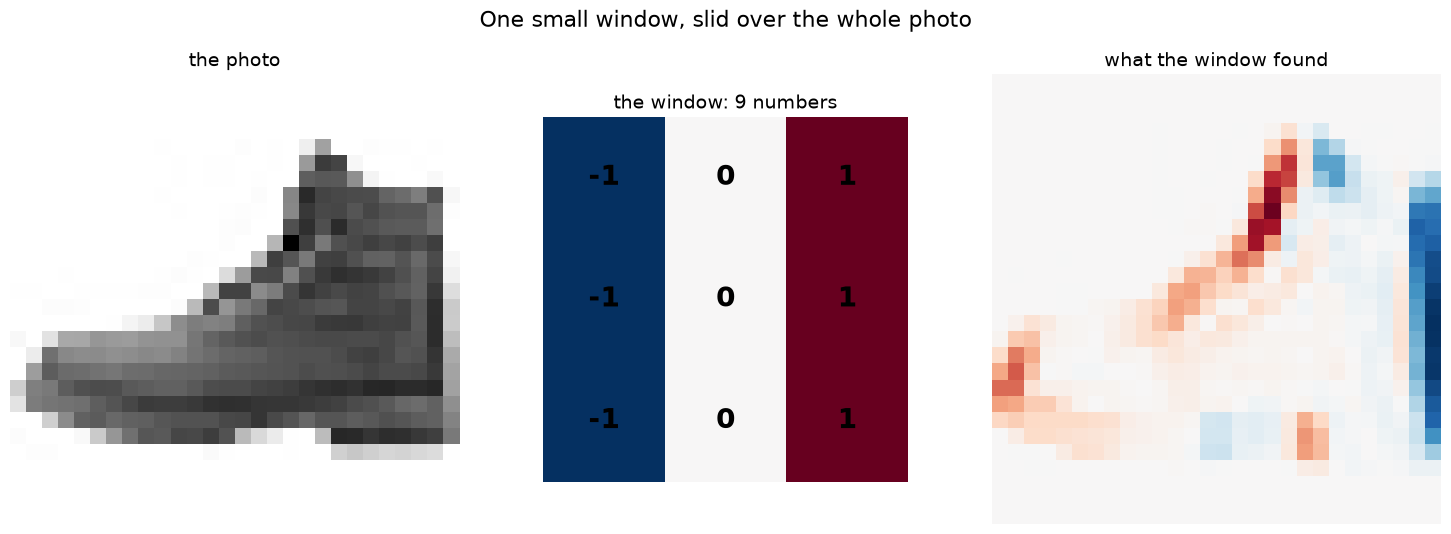

In [11]:
edge = torch.tensor([[-1., 0, 1],
                      [-1, 0, 1],
                      [-1, 0, 1]])         # right side minus left side
boot = X_val[0:1]
found = nn.functional.conv2d(boot, edge.reshape(1,1,3,3), padding = 1)
print(boot.shape, "->", found.shape)
viz.show_window(boot, edge, found)

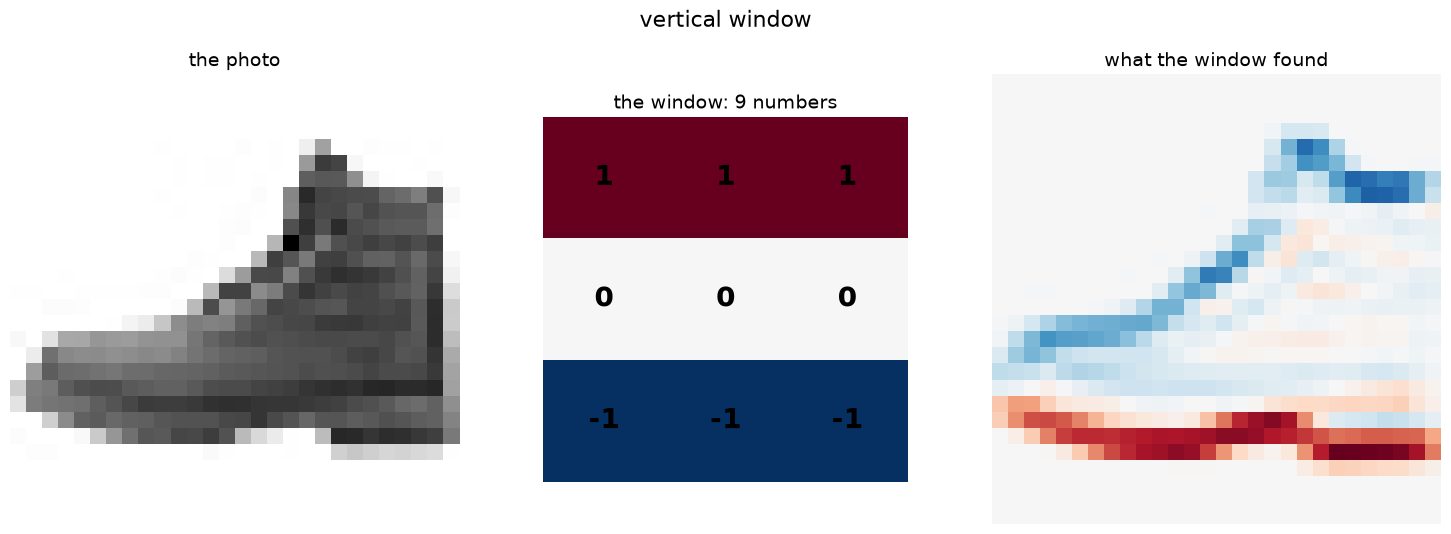

In [13]:
vert = torch.tensor([[1., 1, 1],
                     [0, 0, 0],
                     [-1, -1, -1]])
found = nn.functional.conv2d(boot, vert.reshape(1,1,3,3), padding = 1)
viz.show_window(boot, vert, found, title = "vertical window")

## Pooling

torch.Size([1, 1, 28, 28]) -> torch.Size([1, 1, 14, 14])


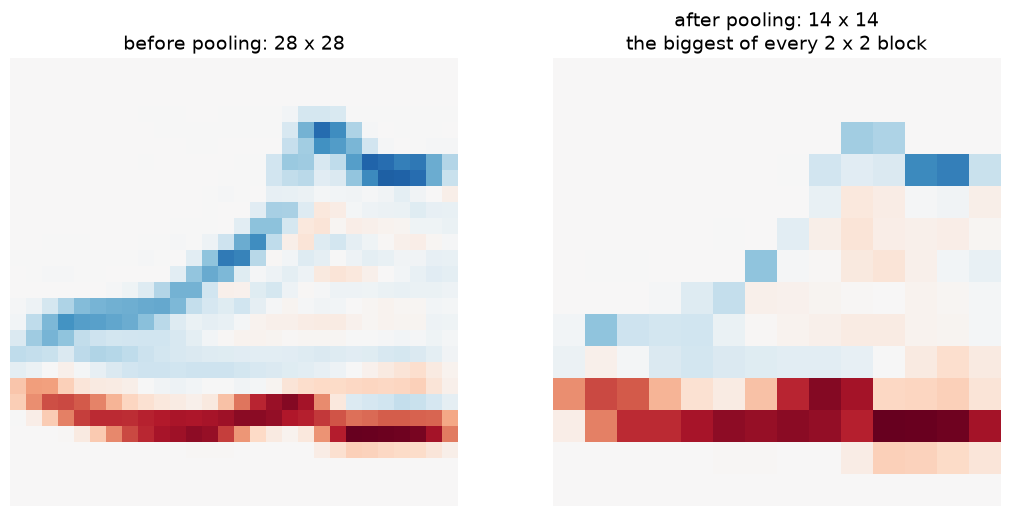

In [14]:
pool = nn.MaxPool2d(2)                ## The biggest of every 2 by 2 matrix
print(found.shape, "->", pool(found).shape)
viz.show_pool(found)

Knobs:  20490


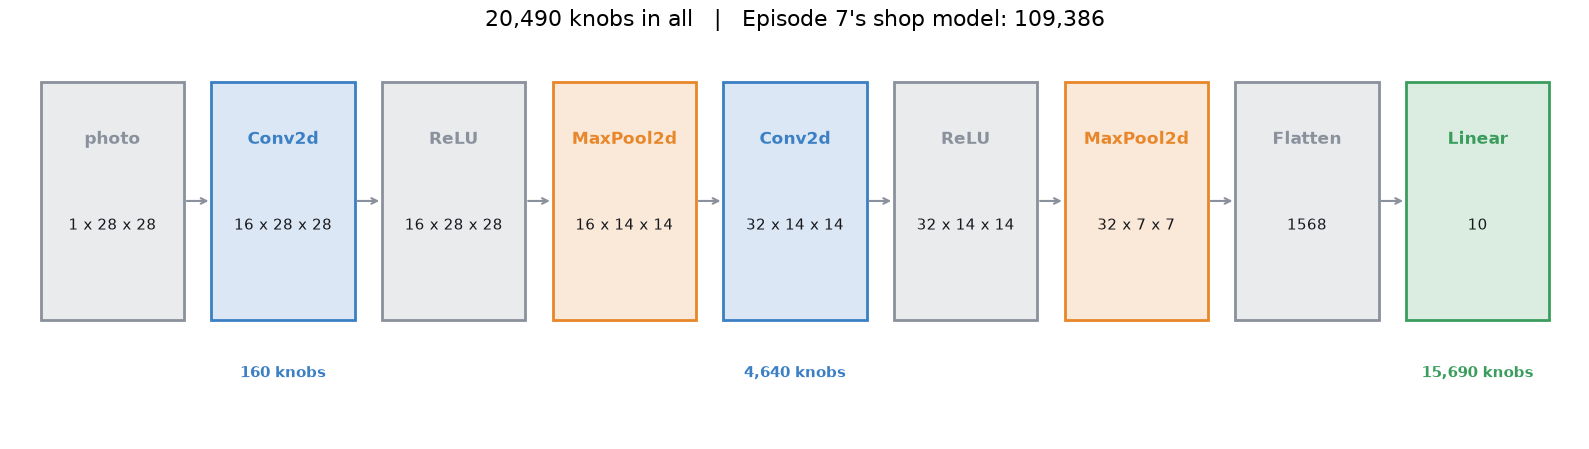

In [15]:
def new_cnn():
    return nn.Sequential(
        nn.Conv2d(1, 16, 3, padding = 1), nn.ReLU(),    # 16 wondows
        nn.MaxPool2d(2),                                # 28 -> 14
        nn.Conv2d(16, 32, 3, padding = 1), nn.ReLU(),
        nn.MaxPool2d(2),                                # 14 -> 7
        nn.Flatten(),                                   # 32 * 7 * 7
        nn.Linear(32 * 7 * 7, 10),
    )

knobs = sum(p.numel() for p in new_cnn().parameters())
print("Knobs: ", knobs)
viz.show_cnn(new_cnn().to(device), compare = 109386)

In [19]:
loss_fn = nn.CrossEntropyLoss()

def fit(model, chart = True, max_epochs = 100):
    optimizer = torch.optim.Adam(model.parameters(), lr = 0.001)
    loader = DataLoader(TensorDataset(X_train, y_train),
                        batch_size = 64, shuffle = True)
    best_acc, bad_epochs = 0, 0
    for epoch in range(1, max_epochs+1):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            loss = loss_fn(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        mock = accuracy(model, X_val, y_val)
        if chart:
            practice = accuracy(model, X_train, y_train)
            viz.live_chart(epoch, practice, mock)
        if mock > best_acc:
            best_acc, best_epoch, bad_epochs = mock, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad_epochs += 1
        if bad_epochs == 5:
            break
    model.load_state_dict(best_state)
    return best_epoch

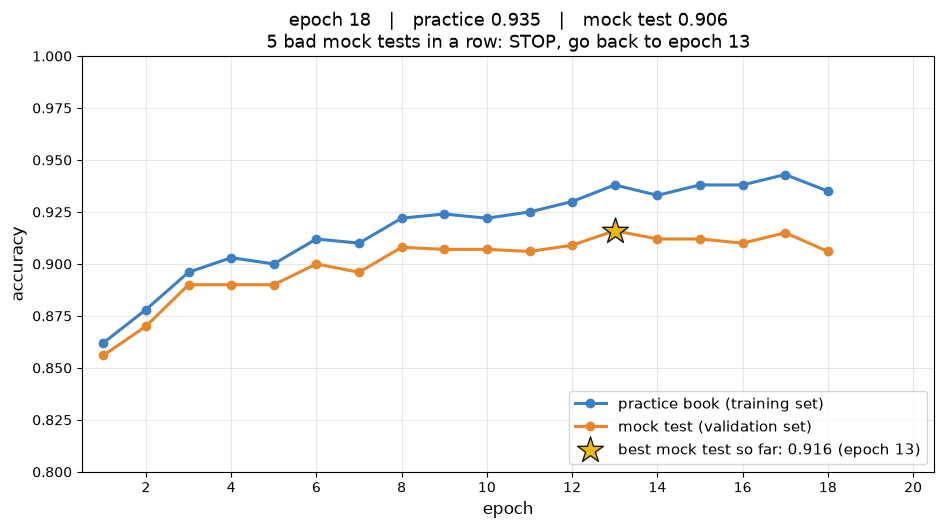

In [20]:
torch.manual_seed(42)
cnn = new_cnn().to(device)
best_epoch = fit(cnn)

Best mock test:  13
Ep 7 shop model:  0.881
CNN            :  0.906


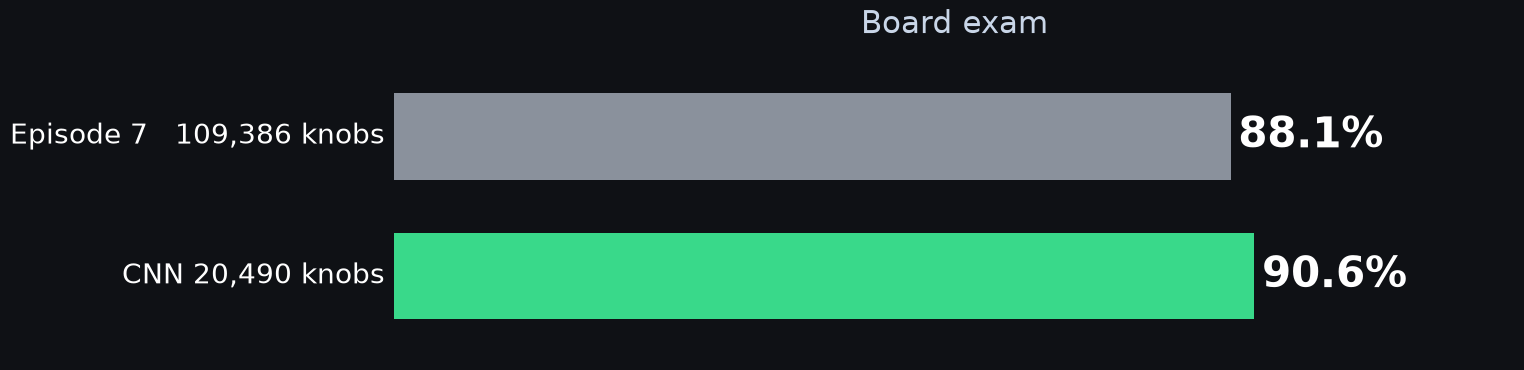

In [21]:
old = accuracy(shop, X_test, y_test)
new = accuracy(cnn, X_test, y_test)
print("Best mock test: ", best_epoch)
print("Ep 7 shop model: ", old)
print("CNN            : ", new)
viz.reveal_board([("Episode 7   109,386 knobs", old, viz.GREY),
                  ("CNN 20,490 knobs", new, viz.NEON)], "Board exam")

[0.916, 0.886, 0.795, 0.527, 0.285, 0.216, 0.201]


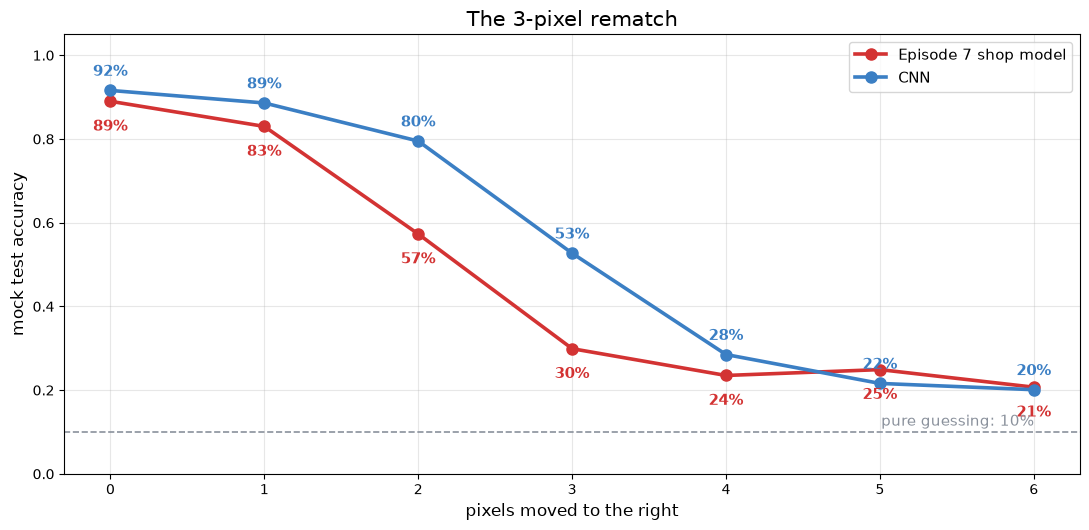

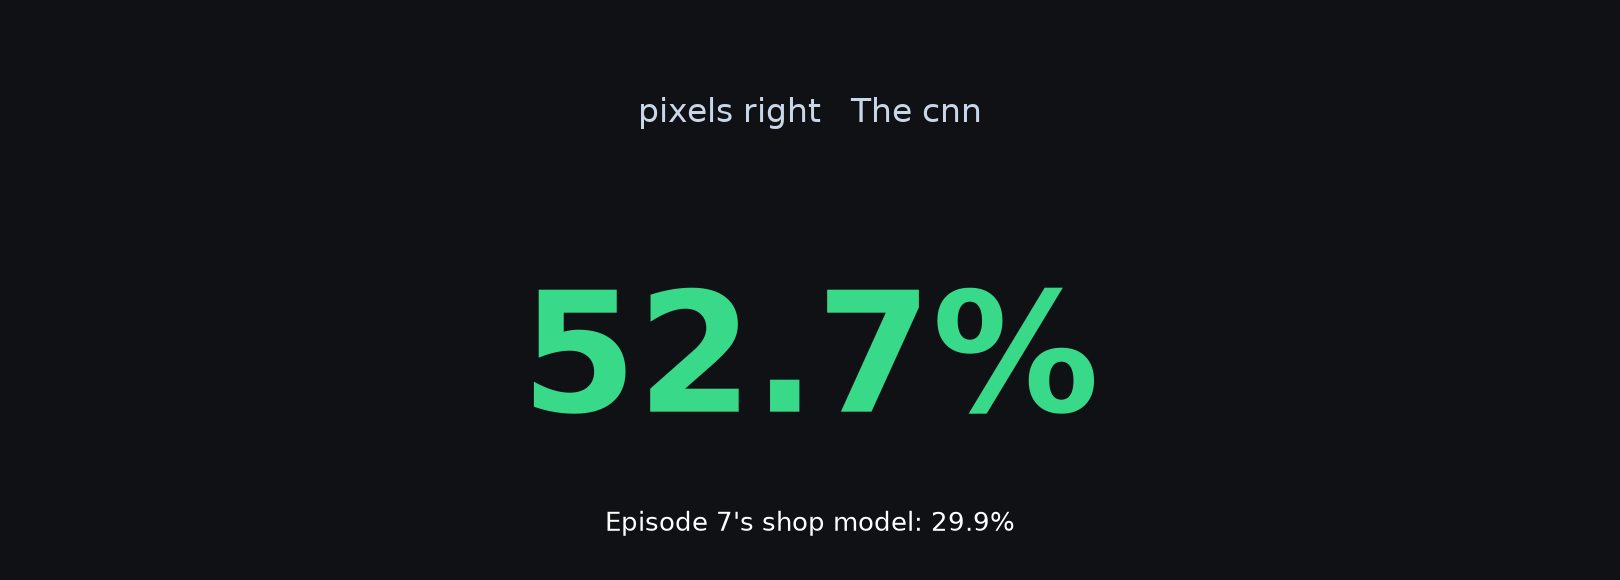

In [22]:
cnn_slid = [accuracy(cnn, shift(X_val, k), y_val) for k in range(7)]
print(cnn_slid)
viz.show_shift_curve({"Episode 7 shop model": shop_slid, "CNN": cnn_slid})
viz.reveal("pixels right   The cnn", cnn_slid[3], start = shop_slid[3],
           note = f"Episode 7's shop model: {shop_slid[3]:.1%}")

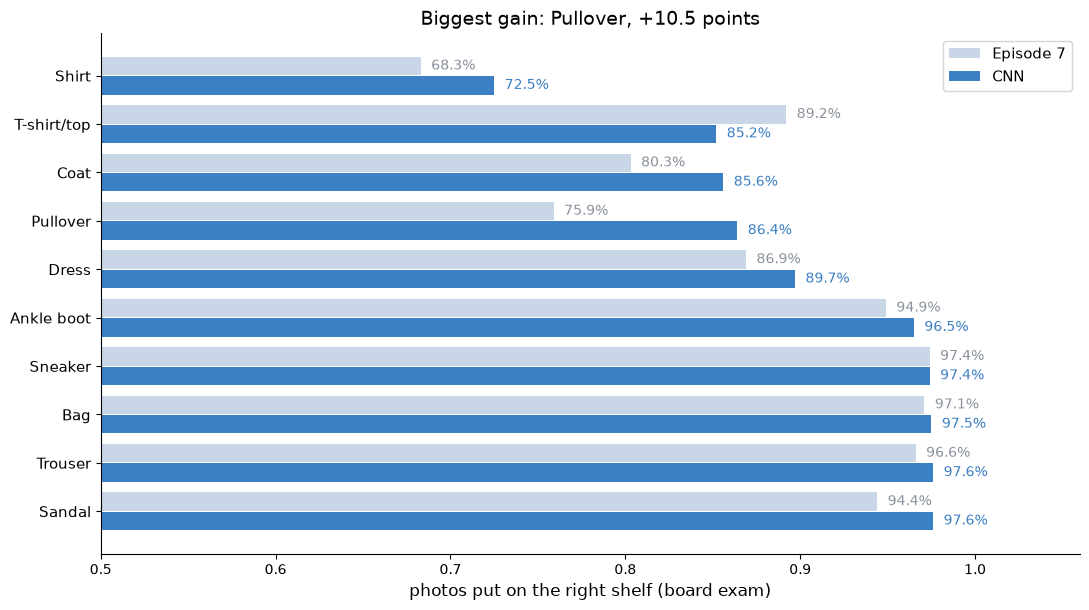

In [24]:
def shelf_scores(model):
    p = picks(model, X_test)
    return [(p[y_test == k] == k).float().mean().item() for k in range(10)]

viz.show_shelf_compare(shelf_scores(shop), shelf_scores(cnn), classes)

(9098, 0.898)


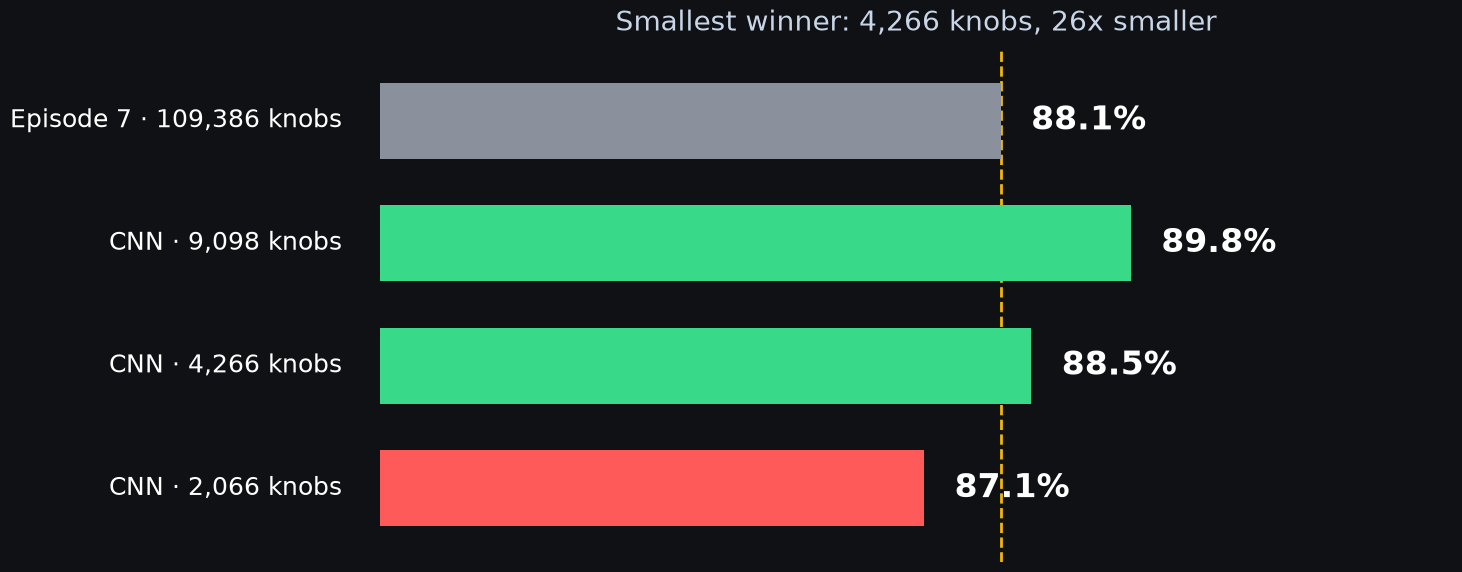

(4266, 0.885)
(2066, 0.871)


In [25]:
def small_cnn(a, b):
    return nn.Sequential(
        nn.Conv2d(1, a, 3, padding = 1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(a, b, 3, padding = 1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(), nn.Linear(b * 7 * 7, 10),
    )

race = []
for a, b in [(8, 16), (4, 8), (2, 4)]:
    torch.manual_seed(42)
    m = small_cnn(a, b).to(device)
    fit(m, chart = False, max_epochs = 30)
    size = sum(p.numel() for p in m.parameters())
    race.append((size, accuracy(m ,X_test, y_test)))
    print(race[-1])
    viz.leaderboard(race, old, 109386, final = len(race)== 3)

## What did CNN taught itself

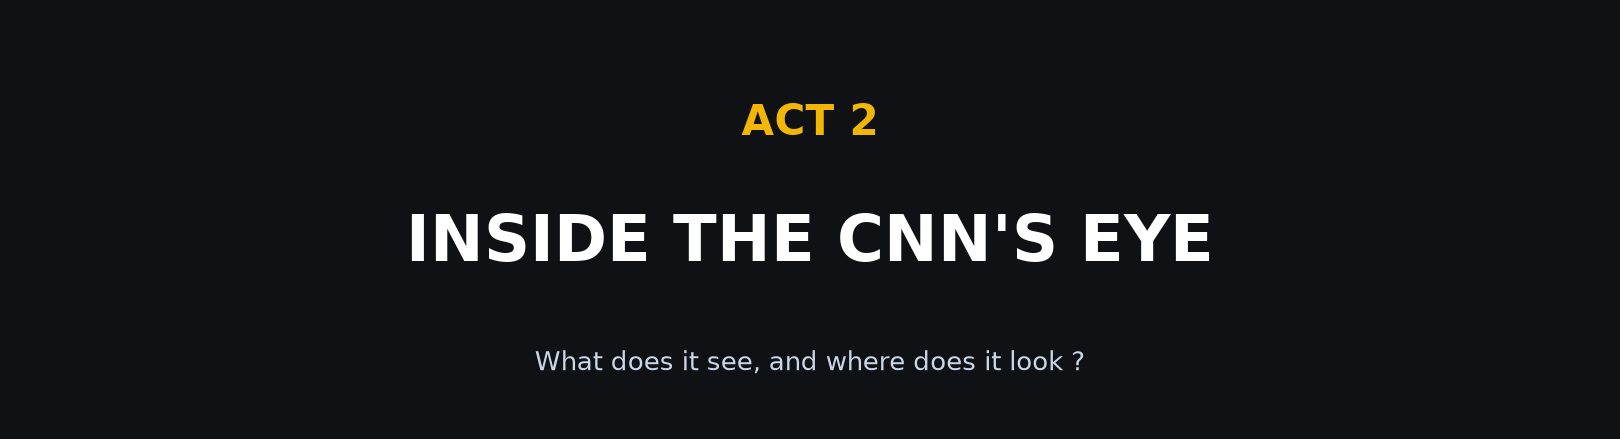

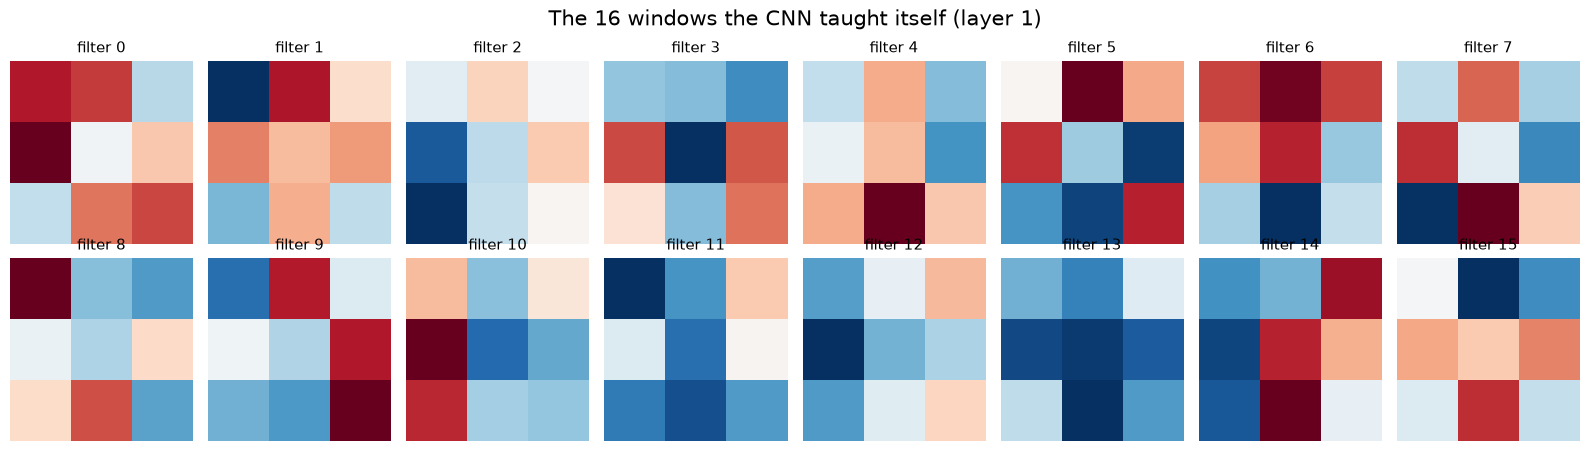

In [26]:
viz.act(2, "Inside the CNN's eye",
        "What does it see, and where does it look ?")
viz.show_filters(cnn[0].weight)

In [27]:
viz.open_in_paint("my_drawing.png")

Paint is open. Draw, then Ctrl+S, then come back here.


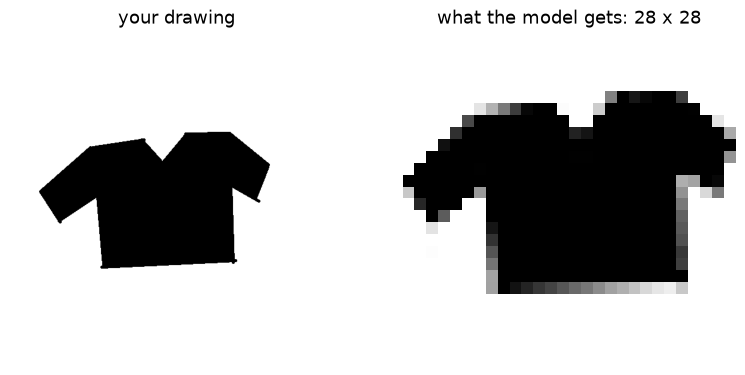

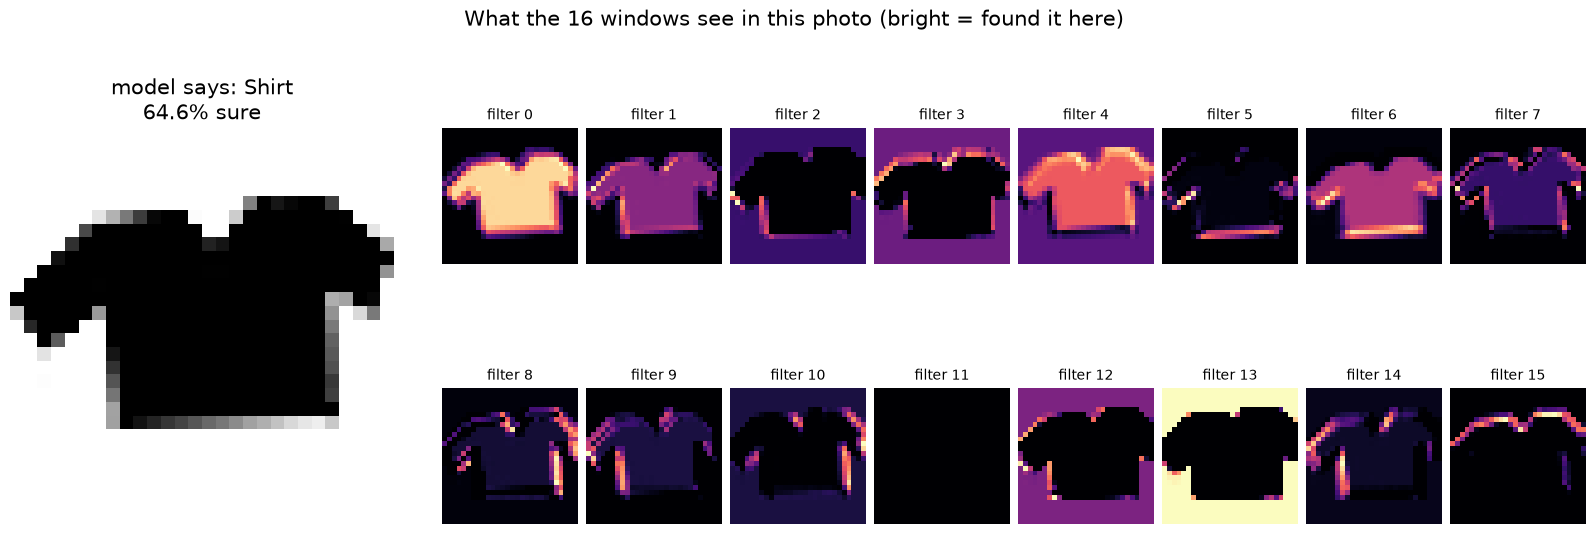

In [ ]:
mine = viz.load_drawing("my_drawing.png")
viz.show_maps(cnn, mine, classes)

In [ ]:
d_drawing("my_drawing.png")
viz.show_maps(cnn, mine, classes)